# persistance/01 — temporal persistence of the goal encoding *(new corpus)*

Replicates `clock/14_goal_retention.ipynb` §2 (per-token read-out table) and §3 (affinity trajectory
across a sub-goal's implementation) on the **current** multi-predicate corpus (`src.diff.data.multi_predicate_setups`,
the `multi_pred` family used by the kv/q-transfer experiments) and the **current** goal-head JSON sets (250 / 122).

**Question:** once the model has committed to a sub-goal at its `{var} =` pivot, is that encoding *retained*
across the tokens that implement it (persistence), or *recomputed* line by line?

- §2 = qualitative read-outs to eyeball (is the verbalization stable across the sub-goal's tokens?).
- §3 = the affinity trajectory: cos(pivot encoding, encoding at 20/40/60/80/100% of the implementation),
  with the four contrast curves. Retention ⇒ curve (i) stays high & flat while (iii)/(iv) stay low.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, math, json, random, logging
sys.path.append("../..")                      # notebooks/persistance -> repo root
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "6,7")   # 32B ~63GB; set to free GPU(s)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import matplotlib.pyplot as plt
from rich.console import Console, Group
from rich.theme import Theme
from rich.table import Table
from rich.text import Text
from rich.box import SIMPLE_HEAVY
from rich.panel import Panel
from rich.markup import escape
from src.utils import logging_utils, env_utils
os.chdir(env_utils.PROJECT_ROOT); sys.path.insert(0, env_utils.PROJECT_ROOT)   # anchor CWD + imports to repo root so head_sets/ , data/ paths resolve
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)   # highlight=False: don't green token strings
def rich_print(*a, **k): console.print(*a, **k)

## 0. Model · goal heads · encoding primitive

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER, N_HEADS = mt.n_layer, mt.n_heads
SLUG = MODEL_NAME.split("/")[-1]
print(f"n_layer={N_LAYER}  n_heads={N_HEADS}  n_embd={mt.n_embd}  head_dim={mt.head_dim}")

2026-09-20 16:30:14 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-09-20 16:30:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 16:30:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-20 16:30:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 16:30:14 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-09-20 16:30:15 httpx INFO     HTTP Re

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-09-20 16:30:39 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-09-20 16:30:39 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-09-20 16:30:39 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_heads=40  n_embd=5120  head_dim=128


In [3]:
# ── goal heads (current JSON head sets — NOT the old head_mask.pt) ──
from scripts.evaluation.eval_goalscope import load_json_heads

HEAD_SETS = {
    250: f"head_sets/{SLUG}/goal_topk/goal__lam20_top250.json",
    122: f"head_sets/{SLUG}/goal__lam20_thr0.9_band25-56.json",
}
HEAD_BUDGET = 122                                   # <- toggle 250 / 122
goal_heads = load_json_heads(HEAD_SETS[HEAD_BUDGET], N_LAYER, N_HEADS)
print(f"{HEAD_BUDGET} goal heads · layers {min(l for l,_ in goal_heads)}-{max(l for l,_ in goal_heads)}")

122 goal heads · layers 28-55


In [4]:
# ── goal-encoding primitive (same as clock/14): the goal heads' summed residual write ──
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.tokens import prepare_input

@torch.no_grad()
def goal_encoding(text, positions, heads=None, patch_interface=None):
    """(n_positions, n_embd) float32 — goal-head residual contribution at each position.
    `text` may be a str or a pre-tokenized TokenizerOutput (positions must match its tokenization)."""
    heads = goal_heads if heads is None else heads
    inp = prepare_input(prompts=text, tokenizer=mt) if isinstance(text, str) else text
    vecs = collect_head_steering_vecs(mt, inp, heads, token_positions=list(positions),
                                      patch_interface=patch_interface)
    return vecs[0]                                  # batch of 1 -> (n_pos, n_embd)

def cos(a, b):
    return float(torch.nn.functional.cosine_similarity(a.float(), b.float(), dim=-1))

## 1. Corpus (multi-predicate) — full rollout + per-condition spans

In [5]:
# ── §1 corpus: full multi-predicate rollouts (LETTER naming, seed `a=` prefilled & ignored) ──
import src.diff.data as DATA
from scripts.evaluation.eval_goalscope import _chat_prompt, greedy_continue, ALL_DATATYPES

N_SPECS   = 8
N_COND    = [3, 4]          # task sizes to mix over (>=2)
SEED      = 1123
DATATYPE  = "list[str]"     # int | str | list[int] | list[str]
GEN_MAX_NEW = 256

def build_full_prompt(inst):
    """WHOLE-function prompt in LETTER naming: signature + the FIRST predicate prefilled as
    `a = <impl>` so the model adopts a/b/c/... and writes EVERY remaining condition (the rollout
    §3 needs). The seed `a` lives in the prompt, so it never appears in `gen` and is IGNORED in the
    analysis — only b, c, ... are probed."""
    preds = inst._preds_for(inst.src_frontier)
    descs = [p.description for p in preds]
    q = DATA._question(descs, inst.datatype, inst.var_name, inst.src_lang, "listed")
    q = q.replace("computes:", "computes in sequential order:")
    base = "<code>\n" + DATA._signature(inst.datatype, inst.var_name, inst.src_lang)
    seed = DATA._assign_line(preds[0], inst.var_name, inst.src_lang, res_name="a")   # `    a = ...`
    base = base + "\n" + seed
    return _chat_prompt(mt, q, base), preds

def offsets_of(full_text):
    enc = prepare_input(prompts=full_text, tokenizer=mt, return_offsets_mapping=True)
    return [tuple(p) for p in enc.pop("offset_mapping")[0].tolist()]

def _toks_in(offsets, a_char, b_char):
    return [t for t,(a,b) in enumerate(offsets) if b>a and a<b_char and b>a_char]

PIVOT_RE = re.compile(r"(?m)^[ \t]+([A-Za-z_]\w*)\s*=(?!=)")

def _desc_for(var, preds):
    """letter var (a=0,b=1,...) -> its predicate description by position."""
    j = ord(var) - ord("a")
    return preds[j].description if 0 <= j < len(preds) else "?"

def _nl(s):
    return s.replace("\\n", "\n")            # defensive: render real line breaks in prints

def analyze(inst):
    """(prompt, text, offsets, conds[]) — greedy rollout after the seed `a = ...`, then per-`{var}=`
    spans. Condition `a` is prefilled and skipped; only b, c, ... are returned (contiguous idx)."""
    prompt, preds = build_full_prompt(inst)
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    gen = greedy_continue(mt, **inp, max_new_tokens=GEN_MAX_NEW)
    text = prompt + gen; offs = offsets_of(text); g0 = len(prompt)
    pivots = list(PIVOT_RE.finditer(gen))
    # hard stop: the trailing `return …` / `</code>` is NOT part of any condition's impl
    _ret = re.search(r"(?m)^[ \t]*return\b", gen)
    _fence = gen.find("</code>")
    body_end = min(_ret.start() if _ret else len(gen),
                   _fence if _fence >= 0 else len(gen), len(gen))
    conds = []
    for i, m in enumerate(pivots):
        var = m.group(1)
        if var == "a":                       # the prefilled seed (should not appear in gen) — skip
            continue
        eq_char = g0 + gen.index("=", m.start())
        eq_tok  = next((t for t,(a,b) in enumerate(offs) if a<=eq_char<b), None)
        seg_start = eq_char + 1
        next_start = pivots[i+1].start() if i+1 < len(pivots) else len(gen)
        seg_end   = g0 + min(next_start, body_end)
        impl = [t for t in _toks_in(offs, seg_start, seg_end) if eq_tok is not None and t > eq_tok]
        if eq_tok is not None and impl:
            conds.append(dict(idx=len(conds), var=var, eq=eq_tok, impl=impl,
                              impl_text=text[eq_char+1:seg_end].strip(),
                              desc=_desc_for(var, preds)))
    return dict(inst=inst, prompt=prompt, text=text, offsets=offs, conds=conds, preds=preds)

samples = DATA.multi_predicate_setups(DATATYPE, n_conditions=N_COND, n_samples=N_SPECS,
                                      seed=SEED, naming="letters")
print(f"{len(samples)} samples · datatype={DATATYPE}")
EX = analyze(samples[0])
rich_print(Panel(Text.from_markup(
    f"[white]{escape(_nl(EX['prompt']))}[/white]"
    f"[sea_green3]{escape(_nl(EX['text'][len(EX['prompt']):]))}[/sea_green3]"),
    title="prompt (white) + rollout (green)", border_style="grey42", padding=(0,1)))
for c in EX["conds"]:
    rich_print(f"  cond {c['idx']} `{c['var']}` eq@{c['eq']} impl {c['impl'][0]}..{c['impl'][-1]}"
               f"  [grey58]{escape(c['impl_text'][:120])}[/grey58]  <- {escape(c['desc'][:60])}")


8 samples · datatype=list[str]


╭─────────────────────────────────────── prompt (white) + rollout (green) ────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. Always wrap your code inside <code></code> blocks. Just  │
│ the code, no need to comment or explain.<|im_end|>                                                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `func` which, given a list of strings `words`, computes in    │
│ sequential order:                                                                                               │
│ (1) the length of the longest word                                                                              │
│ (2) the number of words shorter than three characters                                                           │
│ (3) the number of words that end with a consonant                                                               │
│ (4) whether any word is a palindrome                                                                            │
│ <|im_end|>                                                                                                      │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def func(words: list[str]):                                                                                     │
│     a = max(len(w) for w in words) if words else 0                                                              │
│     b = sum(1 for w in words if len(w) < 3)                                                                     │
│     c = sum(1 for w in words if w[-1].lower() not in 'aeiou' and w[-1].isalpha())                               │
│     d = any(w == w[::-1] for w in words)                                                                        │
│     return a, b, c, d                                                                                           │
│ </code>                                                                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

cond 0 `b` eq@147 impl 148..162  sum(1 for w in words if len(w) < 3)  <- the number of words shorter than three 
characters

cond 1 `c` eq@165 impl 166..193  sum(1 for w in words if w[-1].lower() not in 'aeiou' and w[-1].isalpha())  <- 
the number of words that end with a consonant

cond 2 `d` eq@196 impl 197..208  any(w == w[::-1] for w in words)  <- whether any word is a palindrome

## 2. Per-token read-out table  *(qualitative — for eyeballing)*

For a chosen condition, print the GoalScope read-out at each token of its implementation — both flavours:
**F** = faithfulness (natural-language) and **C** = causality (C++). Persistence at the read-out level =
the verbalization keeps naming *this* sub-goal across its tokens (and the *next* condition only appears
once we cross into it).

> **Note (flag):** `GS` below is copied from `clock/14` and was tuned for the 122-band trained mask
> (`additive`, α=0.2, layers 35–46). For the **250-head** set the additive sum is larger — you likely
> want `strategy="additive_norm"` and to re-tune α. Treat the read-outs as a vibe-check, not calibrated.

In [6]:
from src.goals.goalscope import apply_goalscope

GS = dict(selected_heads=goal_heads, strategy="additive_norm", alpha=0.1,
          steer_layer_range=(35, 46), n_steer_tokens="all", max_new_tokens=48)

CAUSAL_PREFIX = "bool check(auto value){"
def build_causality_prompt():
    messages = [
        {"role": "system", "content": "You are a helpful assistant proficient in programming."},
        {"role": "user", "content": "You are implementing a simple C++ function that checks for a condition. Just write the function body, without any comments or explanations. Assume all the necessary headers are already included."},
        {"role": "assistant", "content": CAUSAL_PREFIX},
    ]
    kw = dict(add_generation_prompt=False, continue_final_message=True, tokenize=False)
    try:
        return mt.tokenizer.apply_chat_template(messages, chat_template_kwargs={"enable_thinking": False}, **kw)
    except TypeError:
        return mt.tokenizer.apply_chat_template(messages, **kw)

def readout_table(anz, cond_idx):
    c = anz["conds"][cond_idx]
    positions = [c["eq"]] + c["impl"]
    tok_inp = prepare_input(prompts=anz["text"], tokenizer=mt)         # align positions to our tokenization
    ids = tok_inp.input_ids[0].tolist()
    faith  = {r["pos"]: r for r in apply_goalscope(tok_inp, mt=mt, show=False, include_noncode=False,
                                                   token_positions=positions, **GS)}
    causal = {r["pos"]: r for r in apply_goalscope(tok_inp, mt=mt, show=False, include_noncode=False,
                                                   token_positions=positions,
                                                   goalscope_prompt=build_causality_prompt(), **GS)}
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False,
              title=escape(f"{c['var']} = {c['impl_text'][:90]}"))
    t.add_column("token", no_wrap=True, style="bold", justify="right")
    t.add_column("F (faithfulness / NL)", overflow="fold", style="sea_green3", ratio=1)
    t.add_column("C (causality / C++)", overflow="fold", style="salmon1", ratio=1)
    for p in positions:
        tok = mt.tokenizer.decode([ids[p]])
        f  = (faith.get(p, {}).get("patched_gen") or "").strip().replace("\n", " ↵ ")
        c_ = (causal.get(p, {}).get("patched_gen") or "").strip().replace("\n", " ↵ ")
        t.add_row(repr(tok), escape(f), escape(CAUSAL_PREFIX + c_))
    return t

# 3-4 conditions to eyeball (the seed `a` is excluded; only b, c, ... are in conds)
shown = 0
for s in samples[:4]:
    anz = analyze(s)
    for c in anz["conds"]:
        if len(c["impl"]) >= 3 and shown < 4:
            rich_print(readout_table(anz, c["idx"])); shown += 1
    if shown >= 4:
        break
if shown == 0:
    rich_print("[red]no multi-token conditions found — check §1: did the model write `b = ..., c = ...`?[/red]")


GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


GoalScope[additive_norm]:   0%|          | 0/1 [00:00<?, ?it/s]

                                      b = sum(1 for w in words if len(w) < 3)                                      
                                                                                                                   
    token   F (faithfulness / NL)                               C (causality / C++)                                
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
     ' ='   Counting lines where length is less than 1.         bool check(auto value){return                      
                                                                count_if(begin(value), end(value), [](auto x){     
                                                                return x < 5; }); }                                
   ' sum'   I'm counting lines shorter than 3 characters.       bool check(auto value){return value < 3; }         
      '('   Checking if the length of the string is less than   bool check(auto value){return value.size() < 3; }  
            3.                                                                                                     
      '1'   I'm counting lines where the length of the string   bool check(auto value){return value < 5; }         
            is less than 1.                                                                                        
   ' for'   Checking if the length of the string is less than   bool check(auto value){return value.size() < 3; }  
            1.                                                                                                     
     ' w'   I'm checking if the length of the string is less    bool check(auto value){return value.size() < 3; }  
            than 3.                                                                                                
    ' in'   Checking if the length of each element is less      bool check(auto value){return value < 5; }         
            than 1.                                                                                                
 ' words'   Checking if the length of each element is less      bool check(auto value){return value.size() < 3; }  
            than 3.                                                                                                
    ' if'   I'm checking if the length of the string is less    bool check(auto value){return value.size() < 3; }  
            than 3.                                                                                                
   ' len'   I'm checking if the length of the string is less    bool check(auto value){return value.size() < 3; }  
            than 3.                                                                                                
     '(w'   I'm checking if the length of the string is less    bool check(auto value){return value.size() < 3; }  
            than 3.                                                                                                
      ')'   I'm checking if the length of the string is less    bool check(auto value){return value.size() < 3; }  
            than 3.                                                                                                
     ' <'   I'm checking if the length of the string is less    bool check(auto value){return value.size() < 3; }  
            than 3.                                                                                                
      ' '   I'm checking if the current line is a palindrome.   bool check(auto value){return value ==             
                                                                std::string(value.rbegin(), value.rend()); }       
      '3'   Counting lines that are less than or equal to 1     bool check(auto value){return value < 3; }         
            character.                                                                                             
    ')\n'   I'm checking if the current character is not

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

... (3 outputs left out)

                                       d = any(w == w[::-1] for w in words)                                        
                                                                                                                   
    token   F (faithfulness / NL)                               C (causality / C++)                                
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
     ' ='   I'm checking if any element in the list satisfies   bool check(auto value){return                      
            the condition of being equal to its reverse         std::any_of(value.begin(), value.end(), [](const   
            (indicating a palindrome).                          auto& v){ return v == std::string(v.rbegin(),      
                                                                v.rend()); }); }                                   
   ' any'   I'm checking if the current string is equal to      bool check(auto value){return value ==             
            its reverse.                                        std::string(value.rbegin(), value.rend()); }       
     '(w'   I'm checking if the current string is equal to      bool check(auto value){return value ==             
            its reverse (ignoring case).                        std::string(value.rbegin(), value.rend()); }       
    ' =='   I'm checking if the string is equal to its          bool check(auto value){return value ==             
            reverse.                                            std::string(value.rbegin(), value.rend()); }       
     ' w'   I'm checking if the string is equal to its          bool check(auto value){return value ==             
            reverse.                                            std::string(value.rbegin(), value.rend()); }       
   '[::-'   I'm checking if the string is equal to its          bool check(auto value){return                      
            reverse to determine if it's a palindrome.          std::equal(value.begin(), value.end(),             
                                                                value.rbegin()); }                                 
      '1'   I'm checking if the current string is equal to      bool check(auto value){return                      
            its reverse (ignoring case) to determine if it's    std::equal(value.begin(), value.end(),             
            a palindrome.                                       value.rbegin()); }                                 
      ']'   I'm checking if the current string is equal to      bool check(auto value){return                      
            its reverse (ignoring case) to determine if it's    std::equal(value.begin(), value.end(),             
            a palindrome.                                       value.begin(), [](const auto& c){ return           
                                                                std::equal(c.begin(), c.end(), c.rbegin()); }); }  
   ' for'   Checking if any element in the list is equal to     bool check(auto value){return                      
            its reverse.                                        std::any_of(value.begin(), value.end(), [](const   
                                                                auto& s){ return s == std::string(s.rbegin(),      
                                                                s.rend()); }); }                                   
     ' w'   I'm checking if the current string is a             bool check(auto value){return                      
            palindrome.                                         std::equal(value.begin(), value.end(),             
                                                                value.rbegin()); }                                 
    ' in'   I'm checking if the current string is equal to      bool check(auto value){return                      
            its reverse.                                

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

                            b = any(not w for w in words)  # Check if any word is empty                            
                                                                                                                   
    token   F (faithfulness / NL)                               C (causality / C++)                                
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
     ' ='   I'm checking if there's an empty string in the      bool check(auto value){return value == 0; }        
            list.                                                                                                  
   ' any'   I'm checking if the string is empty.                bool check(auto value){return value.empty(); }     
   '(not'   I'm checking if the string is empty or consists     bool check(auto value){return value.empty(); }     
            only of whitespace.                                                                                    
     ' w'   I'm checking if the string is empty.                bool check(auto value){return value.empty(); }     
   ' for'   I'm checking if the current element is an empty     bool check(auto value){return value.empty(); }     
            string, which indicates that the list contains an                                                      
            empty entry.                                                                                           
     ' w'   I'm checking if the current element is an empty     bool check(auto value){return value.empty(); }     
            string, indicating a blank entry.                                                                      
    ' in'   Checking if the list is empty or contains any       bool check(auto value){return value.empty(); }     
            null elements.                                                                                         
 ' words'   Checking if the list is empty.                      bool check(auto value){return value.empty(); }     
      ')'   Checking if the line is empty or contains only      bool check(auto value){return value == 0; }        
            whitespace.                                                                                            
      ' '   I'm checking if the current line of code is         bool check(auto value){return value < 0; }         
            truthy (evaluates to True for any condition,                                                           
            False otherwise).                                                                                      
     ' #'   I'm checking if any element in the list is          bool check(auto value){return value == 0; }        
            `True`, indicating the presence of an empty                                                            
            string or `None`.                                                                                      
 ' Check'   I'm checking if any element in the list is          bool check(auto value){return value == 0; }        
            `None`.                                                                                                
    ' if'   I'm checking if there's an empty string in the      bool check(auto value){return value == nullptr; }  
            list.                                                                                                  
   ' any'   I'm checking if there's an empty string in the      bool check(auto value){return value.empty(); }     
            list.                                                                                                  
  ' word'   I'm checking if the string is empty.                bool check(auto value){return value.empty(); }     
    ' is'   I'm checking if the string is empty.                bool check(auto value){return value.empty(); }     
 ' empty'   I'm checking if the current element is an em

## 3. Affinity trajectory across the rollout  *(retention vs recomputation)*

**TARGET_SIGNAL** = the goal encoding at a condition's `=` pivot (0% progression). For every condition we
read the encoding at 20/40/60/80/100% of its implementation and compute cosine to its own TARGET_SIGNAL,
plus three contrast curves:

- **(i) same condition** — same pivot vs its own rollout (retention curve).
- **(ii) same pred, diff ctx** — same predicate in a different function.
- **(iii) diff pred, same ctx** / **(iv) diff pred, diff ctx** — the floors.

**Retention** ⇒ (i) flat & high, (ii) below it but above the floors, (iii)/(iv) low. **Recomputation** ⇒
(i) decays toward the floor as the implementation is written. `N_TRIALS` is small by default (vibe-check).

In [12]:
# ── §3a: forward passes → per-condition (pivot + rollout) encodings → the four cosine curves ──
# (numbers only; visualization is the next cell so you can re-plot without re-running forwards)
from tqdm.auto import tqdm

N_TRIALS  = 64                       # contexts (knob — keep small for a quick pass)
PROG_GRID = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
MIN_IMPL  = 4                        # drop conditions with too-short implementations

CONDS = []
for t, s in enumerate(tqdm(DATA.multi_predicate_setups(DATATYPE, n_conditions=N_COND,
                            n_samples=N_TRIALS, seed=SEED, naming="letters"), desc="contexts")):
    anz = analyze(s)
    for c in anz["conds"]:
        if len(c["impl"]) < MIN_IMPL:
            continue
        E = goal_encoding(anz["text"], [c["eq"]] + c["impl"])
        CONDS.append(dict(ctx=t, pred=c["desc"], pivot=E[0].clone(), traj=E[1:].clone(),
                          n_impl=len(c["impl"])))
print(f"{len(CONDS)} conditions from {N_TRIALS} contexts")


contexts:   0%|          | 0/64 [00:00<?, ?it/s]

157 conditions from 64 contexts


curves ready — run the next cell to visualize (no forwards needed to re-plot)


           cos(TARGET_SIGNAL, encoding at x% of rollout) — 157 conditions (122 heads, list; mean ± sem)            
┏━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ comparison   ┃ n pairs ┃           0% ┃          20% ┃          40% ┃          60% ┃          80% ┃        100% ┃
┡━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ i   same     │     157 │ +1.000±0.000 │ +0.754±0.007 │ +0.714±0.008 │ +0.725±0.010 │ +0.750±0.006 │ +0.458±0.0… │
│ condition    │         │              │              │              │              │              │             │
│ ii  same     │    1454 │ +0.917±0.001 │ +0.710±0.002 │ +0.676±0.003 │ +0.675±0.003 │ +0.710±0.002 │ +0.425±0.0… │
│ pred, diff   │         │              │              │              │              │              │             │
│ ctx          │         │              │              │              │              │              │             │
│ iii diff     │     244 │ +0.524±0.008 │ +0.395±0.007 │ +0.371±0.007 │ +0.367±0.007 │ +0.354±0.007 │ +0.473±0.0… │
│ pred, same   │         │              │              │              │              │              │             │
│ ctx          │         │              │              │              │              │              │             │
│ iv  diff     │   22794 │ +0.484±0.001 │ +0.360±0.001 │ +0.338±0.001 │ +0.344±0.001 │ +0.338±0.001 │ +0.348±0.0… │
│ pred, diff   │         │              │              │              │              │              │             │
│ ctx          │         │              │              │              │              │              │             │
└──────────────┴─────────┴──────────────┴──────────────┴──────────────┴──────────────┴──────────────┴─────────────┘

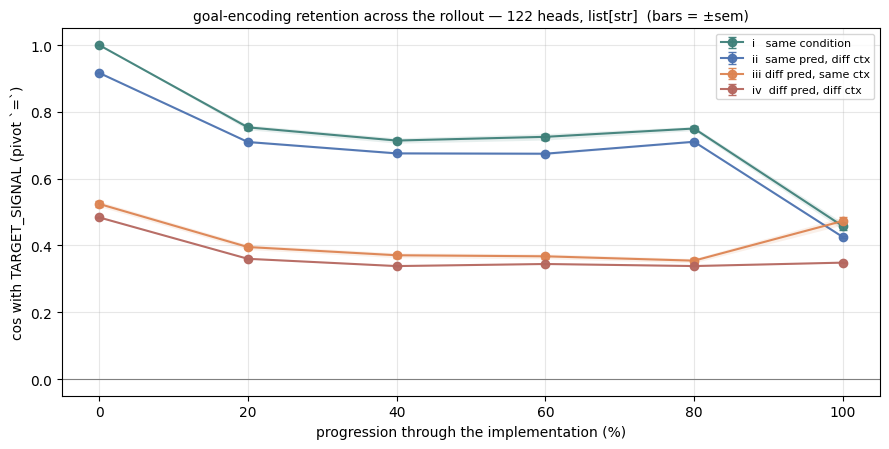

In [16]:
def prog_vec(c, p):
    if p <= 0: return c["pivot"]
    n = c["n_impl"]; return c["traj"][min(n-1, max(0, math.ceil(p*n)-1))]

def _unit(M):
    M = M.float(); return (M / M.norm(dim=-1, keepdim=True)).numpy()

P  = _unit(torch.stack([c["pivot"] for c in CONDS]))
G  = {p: _unit(torch.stack([prog_vec(c, p) for c in CONDS])) for p in PROG_GRID}
pred = np.array([c["pred"] for c in CONDS]); ctx = np.array([c["ctx"] for c in CONDS])
same_pred = pred[:, None] == pred[None, :]; same_ctx = ctx[:, None] == ctx[None, :]
eye = np.eye(len(CONDS), dtype=bool)
MASKS = {"i   same condition": eye,
         "ii  same pred, diff ctx": same_pred & ~same_ctx,
         "iii diff pred, same ctx": ~same_pred & same_ctx,
         "iv  diff pred, diff ctx": ~same_pred & ~same_ctx}
COLOR = {"i   same condition":"#3f8079","ii  same pred, diff ctx":"#4c72b0",
         "iii diff pred, same ctx":"#dd8452","iv  diff pred, diff ctx":"#b5675f"}

# curves[name][p] = (mean, std, sem, n) over all matched off-diagonal (or diagonal) pairs
curves = {}
for name, m in MASKS.items():
    curves[name] = {}
    for p in PROG_GRID:
        v = (P @ G[p].T)[m]
        if len(v):
            mu = float(v.mean()); sd = float(v.std(ddof=1)) if len(v) > 1 else 0.0
            curves[name][p] = (mu, sd, sd/np.sqrt(len(v)), len(v))
        else:
            curves[name][p] = (np.nan, np.nan, np.nan, 0)
print("curves ready — run the next cell to visualize (no forwards needed to re-plot)")

# ── §3b: visualize — table + curves with error bars (decoupled from the forwards above) ──
ERR = "sem"                          # "std" -> ± standard deviation | "sem" -> ± standard error
_ei = 1 if ERR == "std" else 2       # index into (mean, std, sem, n)

tbl = Table(title=f"cos(TARGET_SIGNAL, encoding at x% of rollout) — {len(CONDS)} conditions "
                  f"({HEAD_BUDGET} heads, {DATATYPE}; mean ± {ERR})")
tbl.add_column("comparison"); tbl.add_column("n pairs", justify="right")
for p in PROG_GRID: tbl.add_column(f"{int(p*100)}%", justify="right")
for name in MASKS:
    tbl.add_row(name, str(curves[name][PROG_GRID[0]][3]),
                *[f"{curves[name][p][0]:+.3f}±{curves[name][p][_ei]:.3f}" for p in PROG_GRID])
rich_print(tbl)

fig, ax = plt.subplots(figsize=(9, 4.6)); xs = [p*100 for p in PROG_GRID]
for name in MASKS:
    mu = np.array([curves[name][p][0]  for p in PROG_GRID])
    er = np.array([curves[name][p][_ei] for p in PROG_GRID])
    ax.errorbar(xs, mu, yerr=er, fmt="o-", color=COLOR[name], label=name,
                capsize=3, elinewidth=1, alpha=0.95)
    ax.fill_between(xs, mu-er, mu+er, color=COLOR[name], alpha=0.12, lw=0)
ax.set_xlabel("progression through the implementation (%)")
ax.set_ylabel("cos with TARGET_SIGNAL (pivot `=`)")
ax.set_title(f"goal-encoding retention across the rollout — {HEAD_BUDGET} heads, {DATATYPE}  "
             f"(bars = ±{ERR})", fontsize=10)
ax.axhline(0, color="grey", lw=.8); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


### Notes / caveats
- **Span finder is regex-based** (`^\\s+{var} =` → next such pivot), not the oracle labelling `clock/14` §3
  used. For multi-step predicates with an inner temp-var assignment (`for d in …: d = int(d)`) the span may
  truncate early — good enough for a vibe-check; switch to `src.goals.multistep_label.label_generation` if you
  systematise this.
- **GS read-out config** is the 122-band setting; re-tune (`additive_norm`, α) for 250 heads before trusting §2.
- To draw a **fresh** set of contexts (cache is in-memory here), bump `SEED`. Increase `N_TRIALS` for a real run.